# Proyecto de flujo de datos — Bicis compartidas de Toulouse

**Notebook 3: *concept drift* controlado y estrategias de adaptación (sección 5.5).**

En el flujo real de *pomme* (notebook 2) el *concept drift* es muy leve y el ARF online lo absorbe solo, así que no se puede:
1. medir el **retardo** y las **falsas alarmas** de cada detector frente a un cambio cuya fecha se conoce, ni
2. comparar **estrategias de adaptación** (reiniciar el modelo, modelo en segundo plano, árboles adaptativos…).

Para eso construimos un *concept drift* **fuerte y conocido con datos reales**: el sistema de alerta, que ha aprendido con *pomme*, empieza a recibir el **1 de agosto** los datos de otra estación de Toulouse, como si se desplegara en otro punto de la ciudad. A partir de ese momento cambia la relación entre las variables (hora, día, bicis, tiempo) y la probabilidad de quedarse sin bicis.

Es el mismo planteamiento que los flujos sintéticos de los cuadernos del tema (cambio en una posición conocida), pero con datos reales.

Duración aproximada: 4-5 minutos (casi todo es el ARF con 10 semillas).

## 0. Instalación e imports

In [1]:
import importlib.metadata as metadata
import os
import sys

numpy_antes = metadata.version("numpy")
%pip install -q river
if "google.colab" in sys.modules and metadata.version("numpy") != numpy_antes:
    print("Reiniciando la sesión... después ejecutad desde la celda de los imports")
    os.kill(os.getpid(), 9)
else:
    print("River instalado")

In [2]:
import collections
import math
import time
import warnings

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

import river
from river import datasets, drift, forest, metrics, stream, tree

warnings.filterwarnings("ignore")
print("River:", river.__version__)
pd.set_option("display.width", 160)
pd.set_option("display.max_columns", 30)
pd.set_option("display.max_colwidth", 200)

AZUL, NARANJA, VERDE, ROJO, GRIS, SOMBRA, TINTA = "#2a78d6", "#eb6834", "#1baf7a", "#e34948", "#8a8985", "#e6e5e0", "#2b2b2a"
plt.rcParams.update({
    "figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False,
    "axes.grid": True, "grid.color": SOMBRA, "grid.linewidth": 0.6,
    "axes.edgecolor": GRIS, "axes.titlesize": 11, "axes.titleweight": "bold",
    "axes.titlelocation": "left", "font.size": 9.5,
})

River: 0.26.1


## 1. Construcción del escenario

### 1.1 Flujo de cada estación

La función `construir_flujo` repite la construcción del notebook 1 (una instancia cada 30 minutos, mismas variables, etiqueta "2 bicis o menos dentro de 2 horas") para cualquier estación del dataset `Bikes`.

In [3]:
dataset = datasets.Bikes()
dataset.download()
crudo = pd.read_csv(dataset.path, parse_dates=["moment"]).drop_duplicates()

FREQ, HORIZONTE, UMBRAL_POCAS = "30min", "2h", 2
FESTIVOS = pd.to_datetime(["2016-07-14", "2016-08-15"])
METEO = {"temperature": "temperatura", "humidity": "humedad", "wind": "viento", "clouds": "nubes"}


def construir_flujo(estacion, inicio="2016-06-01"):
    """Flujo regular de 30 minutos de una estación (igual que en el notebook 1)."""
    serie = crudo[(crudo["station"] == estacion) & (crudo["moment"] >= inicio)].set_index("moment").sort_index()
    reg = serie.resample(FREQ, label="right", closed="right").last()
    hay_dato = serie["bikes"].resample(FREQ, label="right", closed="right").count() > 0
    f = pd.DataFrame(index=reg.index)
    f["bicis"] = reg["bikes"].where(hay_dato)
    f["tendencia_1h"] = f["bicis"] - f["bicis"].shift(2)
    f["hora"] = f.index.hour + f.index.minute / 60
    f["dia_semana"] = f.index.dayofweek
    f["es_finde"] = (f.index.dayofweek >= 5).astype(int)
    f["es_festivo"] = f.index.normalize().isin(FESTIVOS).astype(int)
    for original, nuevo in METEO.items():
        f[nuevo] = reg[original].where(hay_dato)
    f["llueve"] = reg["description"].str.contains("rain|drizzle|thunderstorm", na=False).astype(int).where(hay_dato)
    f["movimientos_30min"] = serie["bikes"].diff().abs().resample(FREQ, label="right", closed="right").sum().where(hay_dato)
    f["bicis_2h"] = f["bicis"].reindex(f.index + pd.Timedelta(HORIZONTE)).to_numpy()
    f["pocas_bicis_2h"] = (f["bicis_2h"] <= UMBRAL_POCAS).astype(int).where(f["bicis_2h"].notna())
    f = f.dropna(subset=["bicis", "pocas_bicis_2h"])
    f.index.name = "momento"
    return f


flujos = {e: construir_flujo(e) for e in sorted(crudo["station"].unique())}
pd.DataFrame({e: {"instancias": len(f), "bicis medias": f["bicis"].mean(), "% alerta": 100 * f["pocas_bicis_2h"].mean()}
              for e, f in flujos.items()}).T.round(1)

,instancias,bicis medias,% alerta
metro-canal-du-midi,5715.0,10.1,16.3
place-des-carmes,5615.0,7.1,35.4
place-esquirol,5862.0,13.4,33.8
place-jeanne-darc,5631.0,5.9,34.9
pomme,5980.0,6.5,43.0


### 1.2 Evaluación *prequential* con retraso de la etiqueta

Mismo bucle que en el notebook 2: en cada instancia llegan primero las etiquetas de las predicciones de hace 2 horas (se evalúa, se actualiza el detector y el modelo aprende) y después se predice la instancia nueva. Se añade una opción para **reaccionar al drift**: cuando el detector salta, el modelo se reinicia (se sustituye por uno nuevo).

In [4]:
COLUMNAS_X = ["bicis", "tendencia_1h", "hora", "dia_semana", "es_finde", "es_festivo",
              "temperatura", "humedad", "viento", "nubes", "llueve", "movimientos_30min"]
INICIO_EVALUACION = pd.Timestamp("2016-06-15")      # 2 semanas de aprendizaje inicial


def variables_modelo(x):
    xm = {k: v for k, v in x.items() if k != "momento"}
    xm["hora_sin"] = math.sin(2 * math.pi * x["hora"] / 24)
    xm["hora_cos"] = math.cos(2 * math.pi * x["hora"] / 24)
    return xm


def prequential(fabrica_modelo, instancias, retraso=HORIZONTE, detector=None, reiniciar=False, reinicio_en=None):
    """Evaluación test-then-train con la etiqueta retrasada.
    detector: recibe el bit de error; si reiniciar=True, cada drift (desde INICIO_EVALUACION) sustituye el modelo por uno nuevo.
    reinicio_en: fecha en que el modelo se sustituye por uno nuevo (el 'oráculo' que sabe cuándo ocurre el cambio).
    Devuelve (registro por instancia, fechas de drift, fechas de warning)."""
    retraso = pd.Timedelta(retraso)
    modelo = fabrica_modelo()
    pendientes, registros, drifts, avisos = collections.deque(), [], [], []
    en_warning, reiniciado = False, False
    for x, y in instancias:
        t = x["momento"]
        if reinicio_en is not None and not reiniciado and t >= reinicio_en:
            modelo, reiniciado = fabrica_modelo(), True
        while pendientes and pendientes[0][0] + retraso <= t:
            t0, x0, y0, p0 = pendientes.popleft()
            error = int(p0 != y0)
            registros.append((t0, t, error))
            if detector is not None:
                detector.update(error)
                if t >= INICIO_EVALUACION:
                    if detector.drift_detected:
                        drifts.append(t)
                        en_warning = False
                        if reiniciar:
                            modelo = fabrica_modelo()
                    elif getattr(detector, "warning_detected", False):
                        if not en_warning:
                            avisos.append(t)
                            en_warning = True
                    else:
                        en_warning = False
            modelo.learn_one(x0, y0)
        xm = variables_modelo(x)
        p = modelo.predict_one(xm)
        pendientes.append((t, xm, y, bool(p) if p is not None else False))
    registro = pd.DataFrame(registros, columns=["momento", "revelada", "error"]).set_index("momento")
    return registro, drifts, avisos


def instancias_de(tabla):
    """Recorre una tabla del flujo como pares (x, y), igual que iter_csv."""
    for t, fila in tabla.iterrows():
        x = {k: fila[k] for k in COLUMNAS_X if pd.notna(fila[k])}
        x["momento"] = t
        yield x, bool(fila["pocas_bicis_2h"])

### 1.3 ¿A qué estación se cambia?

Para elegir la estación, medimos cuánto empeora un modelo que ha aprendido con *pomme* cuando, el 1 de agosto, empieza a recibir los datos de cada una de las otras estaciones (`HoeffdingTreeClassifier`, que no es aleatorio). Se compara con un modelo que ha aprendido **solo** con la estación nueva desde junio: la diferencia es lo que "cuesta" haber aprendido otra cosa.

In [5]:
CAMBIO = pd.Timestamp("2016-08-01")
D = pd.Timedelta
filas = {}
for estacion in [e for e in flujos if e != "pomme"]:
    mezcla_e = pd.concat([flujos["pomme"][flujos["pomme"].index < CAMBIO], flujos[estacion][flujos[estacion].index >= CAMBIO]])
    reg_mezcla, _, _ = prequential(tree.HoeffdingTreeClassifier, instancias_de(mezcla_e))
    reg_solo, _, _ = prequential(tree.HoeffdingTreeClassifier, instancias_de(flujos[estacion]))
    filas[estacion] = {
        "error 2 semanas antes (pomme)": 100 * reg_mezcla["error"][CAMBIO - D("14D"):CAMBIO].mean(),
        "error 1ª semana tras el cambio": 100 * reg_mezcla["error"][CAMBIO:CAMBIO + D("7D")].mean(),
        "error ago-oct (viene de pomme)": 100 * reg_mezcla["error"][CAMBIO:].mean(),
        "error ago-oct (solo esa estación)": 100 * reg_solo["error"][CAMBIO:].mean(),
    }
tabla_estaciones = pd.DataFrame(filas).T.round(1)
tabla_estaciones["coste de venir de pomme (puntos)"] = (tabla_estaciones.iloc[:, 2] - tabla_estaciones.iloc[:, 3]).round(1)
tabla_estaciones

,error 2 semanas antes (pomme),error 1ª semana tras el cambio,error ago-oct (viene de pomme),error ago-oct (solo esa estación),coste de venir de pomme (puntos)
metro-canal-du-midi,18.1,12.2,18.6,16.5,2.1
place-des-carmes,18.1,21.8,22.4,23.6,-1.2
place-esquirol,18.3,14.4,17.2,18.8,-1.6
place-jeanne-darc,18.1,28.1,31.4,24.0,7.4


**Elección: *place-jeanne-darc*.** Es la única estación con la que hay un *concept drift* claro: el error salta del 18,1 % al 28,1 % la primera semana y, de agosto a octubre, el modelo que viene de *pomme* falla 7,4 puntos más que uno que ha aprendido solo con esa estación. Con las demás estaciones el cambio apenas cuesta (entre −1,6 y +2,1 puntos): lo aprendido en *pomme* sirve también allí.

### 1.4 El flujo con el cambio

Se guarda como CSV y se lee con `river.stream.iter_csv`, igual que el flujo de los notebooks 1 y 2.

In [6]:
ESTACION_NUEVA = "place-jeanne-darc"
cambio = pd.concat([flujos["pomme"][flujos["pomme"].index < CAMBIO],
                    flujos[ESTACION_NUEVA][flujos[ESTACION_NUEVA].index >= CAMBIO]])
CSV_CAMBIO = "flujo_cambio_estacion.csv"
cambio.to_csv(CSV_CAMBIO, date_format="%Y-%m-%d %H:%M:%S")

def a_numero(v):
    return float(v) if v != "" else None

CONVERTIDORES = {c: a_numero for c in COLUMNAS_X}
CONVERTIDORES["pocas_bicis_2h"] = lambda v: float(v) == 1


def flujo_cambio(ruta=CSV_CAMBIO):
    for x, y in stream.iter_csv(ruta, target="pocas_bicis_2h", converters=CONVERTIDORES,
                                parse_dates={"momento": "%Y-%m-%d %H:%M:%S"}, drop=["bicis_2h"]):
        yield {k: v for k, v in x.items() if v is not None}, y


print(f"{len(cambio):,} instancias: {(cambio.index < CAMBIO).sum():,} de pomme (1 jun-31 jul) y "
      f"{(cambio.index >= CAMBIO).sum():,} de {ESTACION_NUEVA} (1 ago-5 oct)")

5,795 instancias: 2,927 de pomme (1 jun-31 jul) y 2,868 de place-jeanne-darc (1 ago-5 oct)


## 2. Detectores de *concept drift* con un cambio conocido

Ahora sí sabemos dónde está el drift: el **1 de agosto a las 0:00**. Igual que en el notebook comparativo de la asignatura, para cada detector medimos:
- **% de ejecuciones que detectan el cambio** en las 2 semanas siguientes.
- **Retardo** (días desde el cambio hasta la primera detección en esas 2 semanas). Como la etiqueta llega 2 horas tarde, el retardo mínimo posible es de 2 horas.
- **Falsas alarmas antes del cambio** (del 15 de junio al 31 de julio, cuando no hay cambio), por mes.
- **Antelación del *warning***: cuánto antes del drift entra el detector en zona de *warning* (solo los binarios).

Se usan el Hoeffding Tree (determinista) y el ARF con 10 semillas: 11 flujos de errores.

In [7]:
SEMILLAS = range(1, 11)
FABRICAS_DET = {"DDM": drift.binary.DDM, "EDDM": drift.binary.EDDM, "HDDM_A": drift.binary.HDDMA,
                "HDDM_W": drift.binary.HDDMW, "Page-Hinkley": lambda: drift.PageHinkley(mode="up"), "ADWIN": drift.ADWIN}
MODELOS = {"Hoeffding Tree": tree.HoeffdingTreeClassifier,
           **{f"ARF semilla {s}": (lambda s=s: forest.ARFClassifier(n_models=10, seed=s)) for s in SEMILLAS}}

t0 = time.time()
flujos_error = {}
for nombre, fab in MODELOS.items():
    reg, _, _ = prequential(fab, flujo_cambio())
    flujos_error[nombre] = reg
print(f"{len(flujos_error)} ejecuciones en {time.time() - t0:.0f} s")

11 ejecuciones en 74 s


In [8]:
VENTANA = (CAMBIO, CAMBIO + D("14D"))
meses_antes = (CAMBIO - INICIO_EVALUACION).days / 30.4


def vigilar(detector, registro):
    """Bucle de los cuadernos del tema sobre el flujo de errores ya calculado."""
    drifts, avisos, en_warning = [], [], False
    for t, error in zip(registro["revelada"], registro["error"]):
        detector.update(error)
        if t < INICIO_EVALUACION:
            continue
        if detector.drift_detected:
            drifts.append(t)
            en_warning = False
        elif getattr(detector, "warning_detected", False):
            if not en_warning:
                avisos.append(t)
                en_warning = True
        else:
            en_warning = False
    return drifts, avisos


filas, detecciones = [], collections.defaultdict(dict)
for nombre_modelo, reg in flujos_error.items():
    for nombre_det, fab in FABRICAS_DET.items():
        drifts, avisos = vigilar(fab(), reg)
        detecciones[nombre_det][nombre_modelo] = drifts
        dentro = [d for d in drifts if VENTANA[0] <= d < VENTANA[1]]
        antelacion = np.nan
        if dentro:
            previos = [a for a in avisos if CAMBIO <= a <= dentro[0]]
            antelacion = (dentro[0] - previos[0]).total_seconds() / 86400 if previos else np.nan
        filas.append({"detector": nombre_det, "modelo": nombre_modelo,
                      "detecta": bool(dentro),
                      "retardo_dias": (dentro[0] - CAMBIO).total_seconds() / 86400 if dentro else np.nan,
                      "falsas_alarmas_mes": len([d for d in drifts if d < CAMBIO]) / meses_antes,
                      "antelacion_warning_dias": antelacion})
res_det = pd.DataFrame(filas)
g = res_det.groupby("detector", sort=False)
tabla_detectores = pd.DataFrame({
    "% ejecuciones que detectan (2 semanas)": 100 * g["detecta"].mean(),
    "retardo mediano (días)": g["retardo_dias"].median(),
    "retardo mín.-máx. (días)": g["retardo_dias"].agg(lambda x: f"{x.min():.1f}-{x.max():.1f}" if x.notna().any() else "—"),
    "falsas alarmas antes del cambio (por mes)": g["falsas_alarmas_mes"].mean(),
    "antelación del warning (días, mediana)": g["antelacion_warning_dias"].median(),
}).round(1)
tabla_detectores

,% ejecuciones que detectan (2 semanas),retardo mediano (días),retardo mín.-máx. (días),falsas alarmas antes del cambio (por mes),"antelación del warning (días, mediana)"
detector,,,,,
DDM,72.7,7.8,4.8-10.7,1.5,3.3
EDDM,100.0,3.6,0.2-10.5,6.8,5.4
HDDM_A,100.0,2.9,0.2-4.9,2.1,0.0
HDDM_W,100.0,4.1,0.2-4.2,2.2,0.0
Page-Hinkley,90.9,10.5,6.8-10.9,0.0,NaN
ADWIN,100.0,5.5,1.1-11.6,0.1,NaN


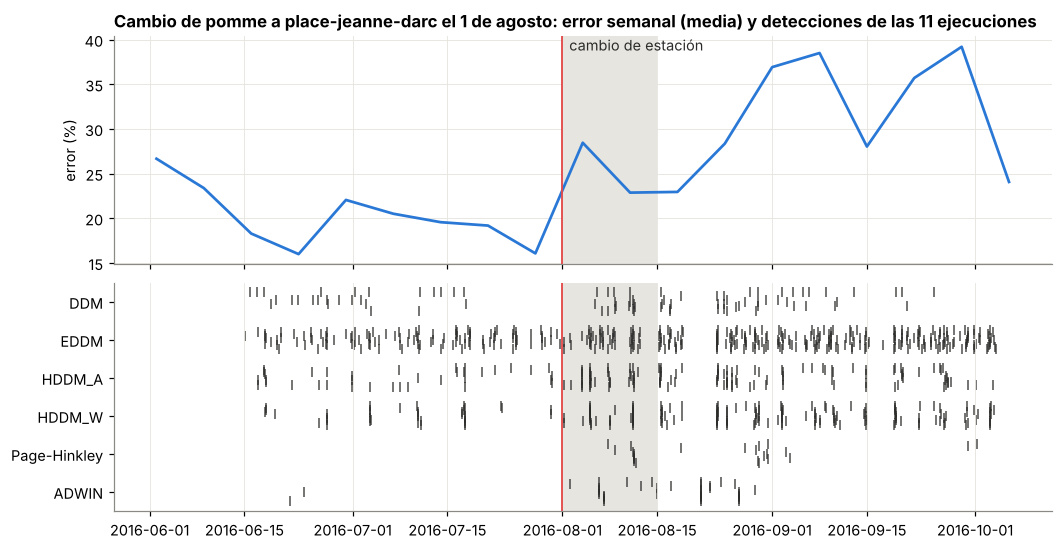

In [9]:
# Error semanal (media de las 11 ejecuciones) y detecciones de cada ejecución
semanas = pd.DataFrame({n: r["error"].resample("W-SUN").mean() for n, r in flujos_error.items()})
semanas.index = semanas.index - pd.Timedelta(days=3)
nombres = list(FABRICAS_DET)

fig, (a1, a2) = plt.subplots(2, 1, sharex=True, figsize=(11, 5.6), gridspec_kw={"height_ratios": [2.2, 2.2], "hspace": 0.08})
a1.plot(semanas.index, 100 * semanas.mean(axis=1), color=AZUL, lw=1.8)
a1.set_ylabel("error (%)")
a1.set_title(f"Cambio de pomme a {ESTACION_NUEVA} el 1 de agosto: error semanal (media) y detecciones de las 11 ejecuciones")
for j, nd in enumerate(nombres):
    for k, (nm, fechas) in enumerate(detecciones[nd].items()):
        a2.scatter(fechas, [j + (k - 5) * 0.05] * len(fechas), marker="|", s=40, lw=1.2, color=TINTA, alpha=0.7)
for ax in (a1, a2):
    ax.axvline(CAMBIO, color=ROJO, lw=1.2)
    ax.axvspan(*VENTANA, color=SOMBRA, lw=0, zorder=0)
a1.text(CAMBIO + D("1D"), a1.get_ylim()[1], "cambio de estación", va="top", color=TINTA)
a2.set_yticks(range(len(nombres)))
a2.set_yticklabels(nombres)
a2.set_ylim(len(nombres) - 0.5, -0.5)
a2.grid(axis="y", visible=False)
plt.show()

**Conclusión: con un cambio claro, los detectores se ordenan por el compromiso entre retardo y falsas alarmas.**

- **HDDM_A** es el más rápido con pocas falsas alarmas: detecta el cambio en todas las ejecuciones con un retardo mediano de 2,9 días, a cambio de unas 2 falsas alarmas al mes antes del cambio. HDDM_W es parecido (4,1 días; 2,2 falsas alarmas al mes).
- **ADWIN** es el más fiable: detecta el cambio en todas las ejecuciones (retardo mediano de 5,5 días) y casi no da falsas alarmas (0,1 al mes).
- **Page-Hinkley** no da ninguna falsa alarma, pero es el más lento (10,5 días) y no detecta el cambio en 1 de las 11 ejecuciones.
- **DDM** solo detecta el cambio en el 73 % de las ejecuciones y tarda 7,8 días: el error sube unos 10 puntos, y DDM necesita una subida mayor respecto a su mínimo histórico.
- **EDDM** detecta rápido (3,6 días), pero con 6,8 falsas alarmas al mes: no sirve para disparar acciones.
- **Warnings:** en DDM y EDDM la zona de *warning* llega de 3 a 5 días antes del drift, un margen para empezar a entrenar un modelo en segundo plano; en HDDM el *warning* coincide con el drift y no aporta.
- **Ningún detector reacciona en horas:** con una etiqueta que llega 2 horas tarde y un cambio de unos 10 puntos de error, todos necesitan **días** de evidencia. Además, después del cambio el error sigue subiendo (septiembre es mucho más difícil en *place-jeanne-darc*) y los detectores sensibles siguen saltando.

## 3. Estrategias de adaptación

Detectar solo sirve si después se hace algo. Comparamos las estrategias del tema:

| Estrategia | Qué hace | Estrategia del tema |
|---|---|---|
| Sin reacción | Hoeffding Tree que sigue aprendiendo online, sin detector | actualización incremental |
| Oráculo | se sustituye el modelo por uno nuevo **justo el 1 de agosto** (nadie sabe eso en la realidad: es la referencia de lo mejor que puede hacer un reinicio) | reentrenamiento completo |
| Reinicio con X | cuando el detector X salta, se sustituye el modelo por uno nuevo | detección + reentrenamiento completo |
| Modelo en segundo plano | `drift.DriftRetrainingClassifier` con DDM: en el *warning* empieza a entrenar un modelo nuevo y en el drift lo sustituye | detección + sustitución |
| Hoeffding Adaptive Tree | árbol con ADWIN en cada nodo: sustituye solo las ramas afectadas | sustitución parcial del modelo |
| ARF | bosque con un detector ADWIN por árbol: sustituye los árboles que empeoran | ensamblado dinámico |

Las estrategias con Hoeffding Tree son deterministas; el Hoeffding Adaptive Tree y el ARF se repiten con 10 semillas.

Métricas: error **antes** del cambio (15 jun-31 jul: el coste de las falsas alarmas), en las **2 semanas siguientes** al cambio (la reacción), de **agosto a octubre** y **total**, y número de reinicios antes y después del cambio.

In [10]:
def medir(registro, drifts=()):
    e = registro["error"]
    return {"error antes (%)": 100 * e[INICIO_EVALUACION:CAMBIO].mean(),
            "error 2 semanas después (%)": 100 * e[CAMBIO:CAMBIO + D("14D")].mean(),
            "error ago-oct (%)": 100 * e[CAMBIO:].mean(),
            "error total (%)": 100 * e[INICIO_EVALUACION:].mean(),
            "reinicios antes": sum(d < CAMBIO for d in drifts),
            "reinicios después": sum(d >= CAMBIO for d in drifts)}


HT = tree.HoeffdingTreeClassifier
t0 = time.time()
estrategias, registros_estr = {}, {}

reg, _, _ = prequential(HT, flujo_cambio())
estrategias["Sin reacción (Hoeffding Tree)"], registros_estr["Sin reacción"] = medir(reg), reg

reg, _, _ = prequential(HT, flujo_cambio(), reinicio_en=CAMBIO)
estrategias["Oráculo: reinicio el 1 de agosto"], registros_estr["Oráculo"] = medir(reg), reg

for nombre_det, fab in FABRICAS_DET.items():
    reg, drifts, _ = prequential(HT, flujo_cambio(), detector=fab(), reiniciar=True)
    estrategias[f"Reinicio con {nombre_det}"] = medir(reg, drifts)
    registros_estr[f"Reinicio con {nombre_det}"] = reg

reg, _, _ = prequential(lambda: drift.DriftRetrainingClassifier(model=tree.HoeffdingTreeClassifier(),
                                                                drift_detector=drift.binary.DDM()), flujo_cambio())
estrategias["Modelo en segundo plano (DDM)"] = medir(reg)

for nombre, fab in {"Hoeffding Adaptive Tree": lambda s: tree.HoeffdingAdaptiveTreeClassifier(seed=s),
                    "ARF": lambda s: forest.ARFClassifier(n_models=10, seed=s)}.items():
    regs = [flujos_error[f"ARF semilla {s}"] if nombre == "ARF" else prequential(lambda s=s: fab(s), flujo_cambio())[0]
            for s in SEMILLAS]
    medidas = pd.DataFrame([medir(r) for r in regs])
    estrategias[f"{nombre} (media de 10 semillas)"] = medidas.mean().to_dict()
    registros_estr[nombre] = regs
print(f"{time.time() - t0:.0f} s")

tabla_estrategias = pd.DataFrame(estrategias).T.round(1)
tabla_estrategias

16 s


,error antes (%),error 2 semanas después (%),error ago-oct (%),error total (%),reinicios antes,reinicios después
Sin reacción (Hoeffding Tree),20.2,22.3,31.4,26.4,0.0,0.0
Oráculo: reinicio el 1 de agosto,20.2,23.7,29.9,25.6,0.0,0.0
Reinicio con DDM,25.9,29.2,32.2,29.4,2.0,15.0
Reinicio con EDDM,23.3,26.5,31.2,27.7,2.0,20.0
Reinicio con HDDM_A,24.4,22.7,30.3,27.7,9.0,20.0
Reinicio con HDDM_W,25.5,19.0,28.6,27.3,5.0,16.0
Reinicio con Page-Hinkley,20.2,25.8,30.4,25.9,0.0,2.0
Reinicio con ADWIN,20.2,22.9,29.6,25.4,0.0,4.0
Modelo en segundo plano (DDM),23.7,29.7,32.8,28.7,0.0,0.0
Hoeffding Adaptive Tree (media de 10 semillas),21.1,21.5,30.0,26.1,0.0,0.0


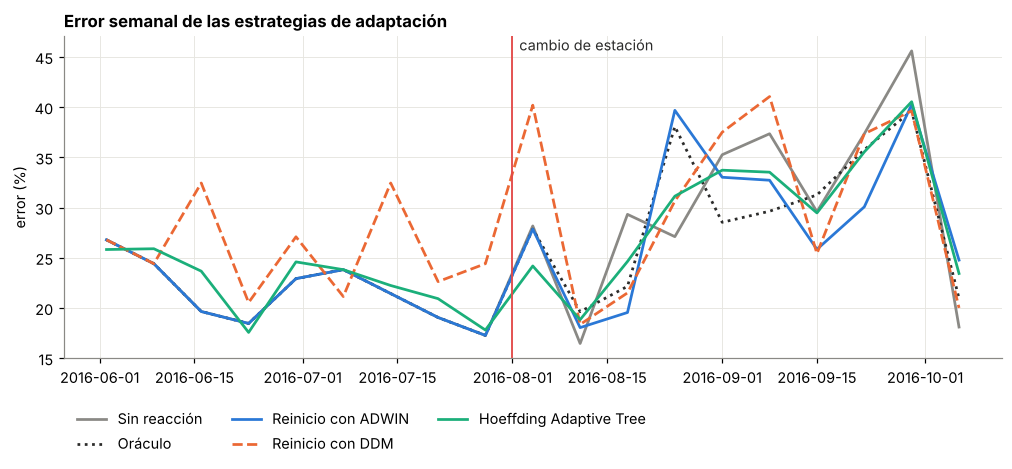

In [11]:
def semanal(reg):
    if isinstance(reg, list):
        s = pd.DataFrame({i: r["error"].resample("W-SUN").mean() for i, r in enumerate(reg)}).mean(axis=1)
    else:
        s = reg["error"].resample("W-SUN").mean()
    s.index = s.index - pd.Timedelta(days=3)
    return 100 * s

fig, ax = plt.subplots(figsize=(11, 3.8))
for nombre, color, ls in [("Sin reacción", GRIS, "-"), ("Oráculo", TINTA, ":"), ("Reinicio con ADWIN", AZUL, "-"),
                          ("Reinicio con DDM", NARANJA, "--"), ("Hoeffding Adaptive Tree", VERDE, "-")]:
    s = semanal(registros_estr[nombre])
    ax.plot(s.index, s.values, color=color, ls=ls, lw=1.8, label=nombre)
ax.axvline(CAMBIO, color=ROJO, lw=1.2)
ax.text(CAMBIO + D("1D"), ax.get_ylim()[1], "cambio de estación", va="top", color=TINTA)
ax.set_title("Error semanal de las estrategias de adaptación")
ax.set_ylabel("error (%)")
ax.legend(frameon=False, ncol=3, loc="upper left", bbox_to_anchor=(0, -0.12))
plt.show()

**Conclusión: reaccionar al drift ayuda poco, y reaccionar a falsas alarmas empeora el sistema.**

- **Reiniciar con ADWIN es la mejor estrategia:** 25,4 % de error total frente al 26,4 % de no reaccionar, y de agosto a octubre (29,6 %) iguala al oráculo que sabe cuándo ocurre el cambio (29,9 %). Combina detectar el cambio siempre y no dar falsas alarmas: no reinicia ninguna vez antes del cambio.
- **El Hoeffding Adaptive Tree** (sustitución parcial) y **el ARF** (ensamblado dinámico) quedan cerca sin detector externo (26,1 % y 25,6 % de error total). El ARF es el mejor antes del cambio (18,6 %) y el que peor reacciona (26,0 % en las 2 semanas siguientes): sustituye sus árboles poco a poco.
- **Reiniciar con DDM, EDDM o HDDM es peor que no hacer nada** (27,3-29,4 % de error total). Sus falsas alarmas reinician el modelo antes del cambio (de 2 a 9 veces) y el error antes del cambio sube del 20,2 % hasta el 25,9 %. Después del cambio, el modelo recién reiniciado falla mucho mientras aprende, el detector vuelve a saltar y se encadenan los reinicios (de 15 a 20). HDDM_W consigue el mejor error de agosto a octubre (28,6 %), pero lo paga antes del cambio.
- **El modelo en segundo plano con DDM** tampoco ayuda (28,7 % de error total): sus avisos y drifts falsos sustituyen el modelo antes del cambio (el error antes del cambio sube del 20,2 % al 23,7 %).
- **Las ganancias son pequeñas** (como mucho 1 punto de error total): reiniciar también tira lo que sigue sirviendo (el ciclo diario es parecido en las dos estaciones), y septiembre en *place-jeanne-darc* es difícil para cualquier modelo (todas las estrategias superan el 35 % de error en algunas semanas).
- **Lección:** para disparar un reentrenamiento importa más **no dar falsas alarmas** que detectar rápido. Con un detector conservador (ADWIN, Page-Hinkley) reiniciar es seguro; con uno sensible (EDDM, HDDM, DDM) es mejor un modelo que se adapte solo (Hoeffding Adaptive Tree, ARF).

## 4. Resumen

| Pregunta | Respuesta |
|---|---|
| ¿Qué detector detecta antes el cambio con pocas falsas alarmas? | **HDDM_A**: 2,9 días de retardo mediano, 2,1 falsas alarmas al mes |
| ¿Cuál es el más fiable? | **ADWIN**: detecta siempre (5,5 días) y casi no da falsas alarmas (0,1 al mes) |
| ¿Cuál no sirve aquí? | **EDDM** (6,8 falsas alarmas al mes) y **DDM** (solo detecta el 73 % de las veces, en 7,8 días) |
| ¿Mejor estrategia de adaptación? | **Reiniciar el modelo cuando salta ADWIN**: iguala al oráculo de agosto a octubre y es la mejor en el total |
| ¿Peor estrategia? | Reiniciar con detectores sensibles (DDM, EDDM, HDDM): peor que no reaccionar |
| ¿Y sin detector externo? | El Hoeffding Adaptive Tree y el ARF se adaptan solos y quedan cerca de la mejor estrategia |